In [1]:
import pandas as pd
import numpy as np

from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import set_config
set_config(transform_output="pandas")

In [2]:
sheet_id = '16svB_80prjxM0l19MiSnbBBNi1ms5o3xNDDTtc1HQMA'
sheet_gid = "659717095"
url = f"https://docs.google.com/spreadsheets/d/{sheet_id}/export?format=csv&gid={sheet_gid}"
moosic_df = pd.read_csv(url)
moosic_df

,Unnamed: 0,name,artist,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,type,duration_ms,time_signature,id,html
0,0,Se Eu Quiser Falar Com Deus,Gilberto Gil,0.6580,0.25900,11,-13.141,0,0.0705,0.694,0.000059,0.9750,0.3060,110.376,NaN,256213,4,1n7JnwviZ7zf0LR1tcGFq7,https://open.spotify.com/track/1n7JnwviZ7zf0LR...
1,1,Saudade De Bahia,Antônio Carlos Jobim,0.7420,0.39900,2,-12.646,1,0.0346,0.217,0.000002,0.1070,0.6930,125.039,NaN,191867,4,5QGM1U0eCYrQuwSJwTm5Zq,https://open.spotify.com/track/5QGM1U0eCYrQuwS...
2,2,"Canta Canta, Minha Gente ...",Martinho Da Vila,0.8510,0.73000,2,-11.048,1,0.3470,0.453,0.000063,0.1240,0.9050,93.698,NaN,152267,4,0NLIFSZxPzQhCwnkn5PJYs,https://open.spotify.com/track/0NLIFSZxPzQhCwn...
3,3,Mulher Eu Sei,Chico César,0.7050,0.05020,4,-18.115,1,0.0471,0.879,0.000041,0.3860,0.5240,106.802,NaN,186227,4,3mXqOdlLE1k67WsAxryPFs,https://open.spotify.com/track/3mXqOdlLE1k67Ws...
4,4,Rosa Morena,Kurt Elling,0.6510,0.11900,6,-19.807,1,0.0380,0.916,0.000343,0.1040,0.4020,120.941,NaN,273680,4,7bSzjzjTkWT2CkIPPdp0eA,https://open.spotify.com/track/7bSzjzjTkWT2CkI...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5230,5230,"1812 Festival Overture, Op. 49: 1812 Overture,...",Pyotr Ilyich Tchaikovsky,0.2020,0.06940,3,-23.390,1,0.0473,0.917,0.715000,0.0832,0.0655,87.906,NaN,995000,4,1aEhYlZtypmipA06SDJ4U3,https://open.spotify.com/track/1aEhYlZtypmipA0...
5231,5231,"Winter Fragments pour ensemble instrumental, s...",Tristan Murail,0.1880,0.10100,6,-21.873,1,0.0442,0.855,0.426000,0.0694,0.0355,83.134,NaN,855000,4,1Gfqe7TAKklmuZf6hxsH6h,https://open.spotify.com/track/1Gfqe7TAKklmuZf...
5232,5232,"Schoenberg: 5 Orchestral Pieces, Op. 16: No. 3...",Arnold Schoenberg,0.0596,0.00093,9,-42.959,1,0.0434,0.951,0.969000,0.0772,0.0344,71.573,NaN,238187,3,2XNwnFrdMDpismp0VUZ7cU,https://open.spotify.com/track/2XNwnFrdMDpismp...
5233,5233,"Serenade For Strings In E, Op.22, B. 52: 1. Mo...",Antonín Dvořák,0.1330,0.02080,4,-29.443,1,0.0419,0.883,0.505000,0.1110,0.0591,67.109,NaN,314307,4,7ucDwgMtE3YJtEfTbuRhy0,https://open.spotify.com/track/7ucDwgMtE3YJtEf...


** PREPROCESSING **
---

---



In [3]:
moosic_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5235 entries, 0 to 5234
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Unnamed: 0        5235 non-null   int64  
 1   name              5235 non-null   object 
 2   artist            5235 non-null   object 
 3   danceability      5235 non-null   float64
 4   energy            5235 non-null   float64
 5   key               5235 non-null   int64  
 6   loudness          5235 non-null   float64
 7   mode              5235 non-null   int64  
 8   speechiness       5235 non-null   float64
 9   acousticness      5235 non-null   float64
 10  instrumentalness  5235 non-null   float64
 11  liveness          5235 non-null   float64
 12  valence           5235 non-null   float64
 13  tempo             5235 non-null   float64
 14  type              0 non-null      float64
 15  duration_ms       5235 non-null   int64  
 16  time_signature    5235 non-null   int64  


**Feature Selection**

In [4]:
moosic_df = pd.read_csv(url)
to_drop = ['Unnamed: 0', 'name', 'artist', 'type', 'id', 'html', 'key', 'mode', 'time_signature']
moosic_df_clean = moosic_df.drop(columns=to_drop)
moosic_df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5235 entries, 0 to 5234
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   danceability      5235 non-null   float64
 1   energy            5235 non-null   float64
 2   loudness          5235 non-null   float64
 3   speechiness       5235 non-null   float64
 4   acousticness      5235 non-null   float64
 5   instrumentalness  5235 non-null   float64
 6   liveness          5235 non-null   float64
 7   valence           5235 non-null   float64
 8   tempo             5235 non-null   float64
 9   duration_ms       5235 non-null   int64  
dtypes: float64(9), int64(1)
memory usage: 409.1 KB


**Correlation Analysis**

In [5]:
! pip install ydata_profiling

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.8/400.8 kB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 18.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 33.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 682.5/682.5 kB 21.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.4/105.4 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.0/72.0 kB 3.5 MB/s eta 0:00:00


In [6]:
from ydata_profiling import ProfileReport

/tmp/ipykernel_4279/44057814.py:1: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


In [7]:
report = ProfileReport(moosic_df_clean)


In [8]:
report

Output hidden; open in https://colab.research.google.com to view.

• energy and loudness have a massive positive correlation because louder songs naturally feel higher in energy.

• acousticness and energy have a strong negative correlation because acoustic songs tend to be much quieter and calmer.

**Scaling/Transforming**

In [9]:
scaler = MinMaxScaler()
scaler

MinMaxScaler()

In [10]:
# Fit the scaler to our data and transform it
# This creates a beautifully scaled DataFrame
moosic_scaled = scaler.fit_transform(moosic_df_clean)

# Peek at the first 5 rows to make sure everything is between 0 and 1
moosic_scaled.head()

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
0,0.680455,0.2590,0.763897,0.076797,0.696787,0.000060,0.987842,0.310660,0.515800,0.059067
1,0.767322,0.3990,0.771967,0.037691,0.217871,0.000002,0.108409,0.703553,0.584322,0.042058
2,0.880041,0.7300,0.798018,0.377996,0.454819,0.000064,0.125633,0.918782,0.437862,0.031590
3,0.729059,0.0502,0.682811,0.051307,0.882530,0.000041,0.391084,0.531980,0.499098,0.040567
4,0.673216,0.1190,0.655228,0.041394,0.919679,0.000348,0.105370,0.408122,0.565171,0.063684


**Feature Extraction: PCA**

In [11]:
# 1. Initialize PCA to find exactly 2 principal components
pca = PCA(n_components=6)

# 2. Transform our scaled data into these 2 new dimensions
moosic_pca = pca.fit_transform(moosic_scaled)

# 3. Check the first 5 rows of our new 2D data
moosic_pca.head()


,pca0,pca1,pca2,pca3,pca4,pca5
0,0.240443,-0.505089,-0.273903,0.526952,0.602512,0.195776
1,-0.208652,-0.383923,0.091840,-0.170559,0.021806,0.099451
2,-0.329209,-0.471175,0.285218,-0.003163,0.023458,-0.142513
3,0.383175,-0.816586,-0.078631,0.106785,0.216104,0.090554
4,0.442463,-0.754861,-0.165663,-0.074711,-0.002005,0.087107


• If a song has a positive number in pca0, it means it pulls heavily toward the traits that dominate Component 1 (e.g., high energy/electronic tracks).


• If a song has a negative number, it means it pulls toward the opposite traits (e.g., quiet/acoustic tracks).

** FROM ALGORITHM TO MODEL **
---


---



In [12]:
# Create empty lists to store our evaluation metrics
inertia_scores = []
silhouette_scores = []

# Loop through different numbers of clusters (from 2 to 10)
K_range = range(5, 51)

for k in K_range:
    # 1. Initialize the model with the current K
    kmeans = KMeans(n_clusters=k, random_state=42, n_init="auto")

    # 2. Fit the model on your scaled data
    kmeans.fit(moosic_pca)

    # 3. Save the inertia score
    inertia_scores.append(kmeans.inertia_)

    # 4. Save the silhouette score
    from sklearn.metrics import silhouette_score
    labels = kmeans.labels_
    silhouette_scores.append(silhouette_score(moosic_scaled, labels))


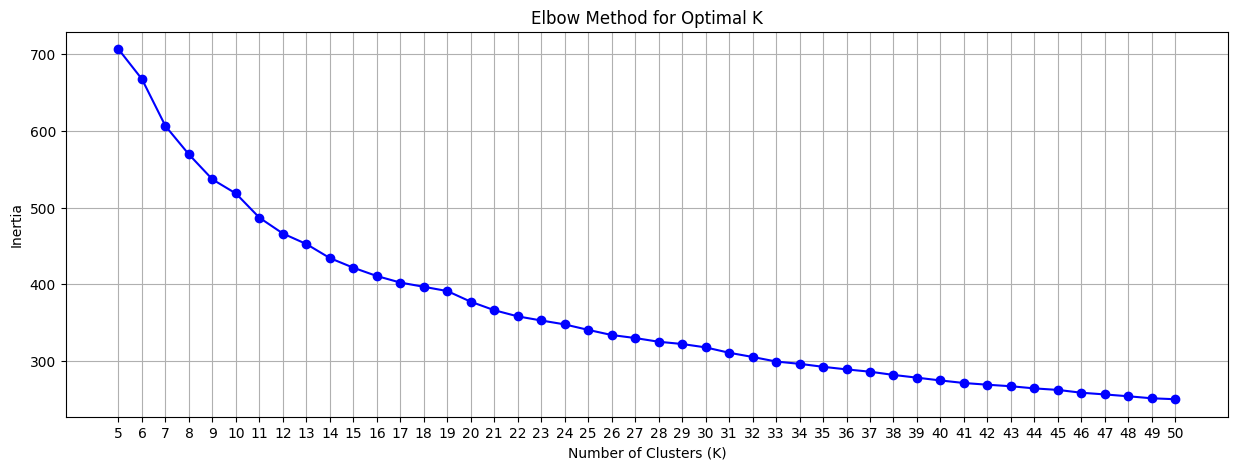

In [13]:
# Plotting the Elbow Method (Inertia)
plt.figure(figsize=(15, 5))
plt.plot(K_range, inertia_scores, marker='o', color='b')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal K')
plt.xticks(K_range)
plt.grid(True)
plt.show()


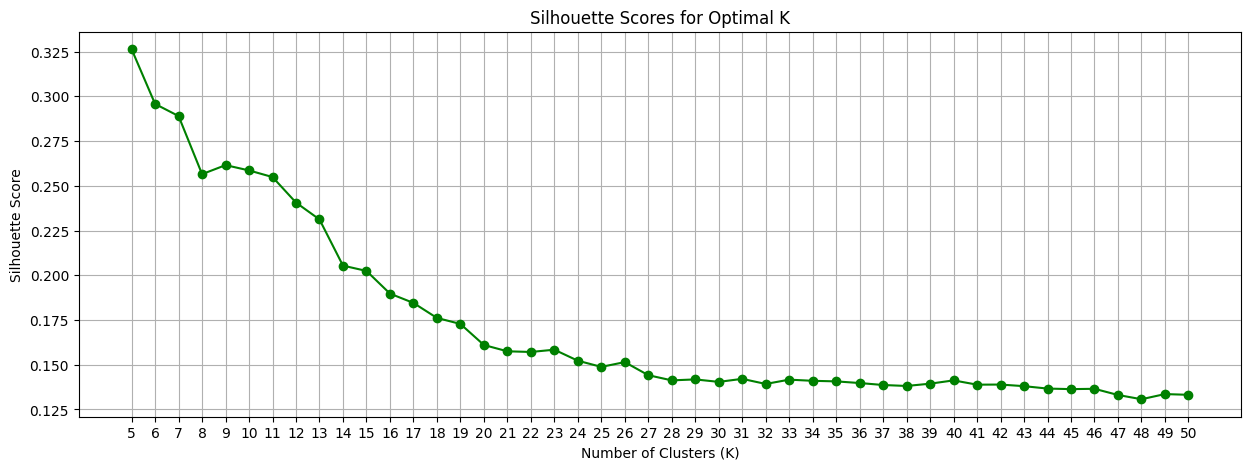

In [14]:
# Plotting the Silhouette Scores
plt.figure(figsize=(15, 5))
plt.plot(K_range, silhouette_scores, marker='o', color='g')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Scores for Optimal K')
plt.xticks(K_range)
plt.grid(True)
plt.show()


---- the Cumulative explained variance method.----

In [15]:
# 1. Initialize PCA without restricting it, to see all components
pca_full = PCA()
pca_full.fit(moosic_scaled)

# 2. Calculate the cumulative variance
import numpy as np
cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)
cumulative_variance

array([0.44961441, 0.7484221 , 0.84785628, 0.89313807, 0.93043132,
       0.95953673, 0.98386942, 0.99371474, 0.99782287, 1.        ])

Text(0.5, 1.0, 'PCA Cumulative Explained Variance')

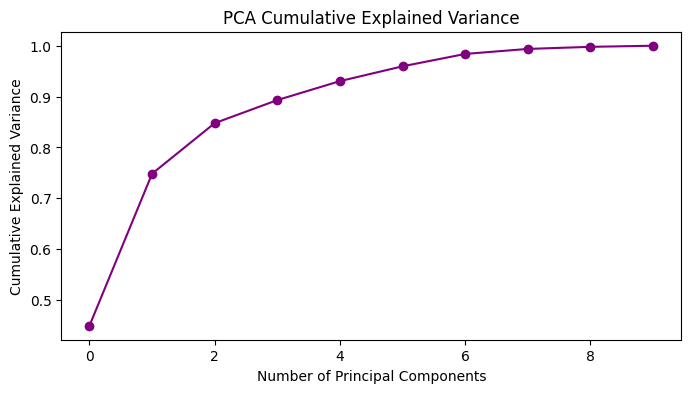

In [16]:

# 3. Plot the cumulative explained variance
plt.figure(figsize=(8, 4))
plt.plot(range(len(cumulative_variance)), cumulative_variance, marker='o', color='purple')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('PCA Cumulative Explained Variance')

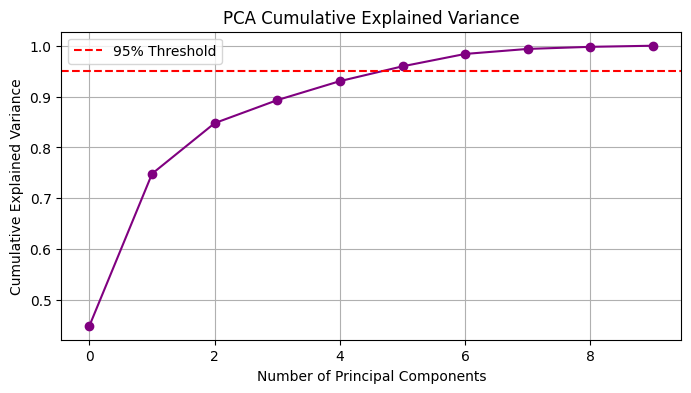

In [17]:

# 3. Plot the cumulative explained variance
plt.figure(figsize=(8, 4))
plt.plot(range(len(cumulative_variance)), cumulative_variance, marker='o', color='purple')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('PCA Cumulative Explained Variance')
plt.axhline(y=0.95, color='r', linestyle='--', label='95% Threshold')
plt.grid(True)
plt.legend()
plt.show()

In [18]:
# Initialize your final KMeans model with 3 clusters
final_kmeans = KMeans(n_clusters=31, random_state=42, n_init="auto")

# Fit the model and predict the cluster labels for each song
cluster_labels = final_kmeans.fit_predict(moosic_pca)

# Add the playlist clusters back into your original dataframe so we can see the song names!
moosic_df_clean['playlist_cluster'] = cluster_labels

# Let's see a quick preview of how the songs are grouped
moosic_df_clean[['playlist_cluster']].head(20)


,playlist_cluster
0,20
1,28
2,9
3,6
4,6
5,6
6,29
7,22
8,28
9,28


• Each row represents one specific song from my dataset.

• The number in the playlist_cluster column is the playlist ID that the KMeans algorithm automatically assigned to that song.

• For example: Song 0 was sent to Playlist 8, while Song 1 went to Playlist 4, and Song 3 went to Playlist 3.

In [19]:
# Let's see how many songs ended up in each playlist
moosic_df_clean['playlist_cluster'].value_counts()


,count
playlist_cluster,
13,300
10,295
14,278
21,264
1,255
8,253
16,250
0,226
5,209


**EVALUATING THE USEFULNESS OF OUR CLUSTERS**

In [20]:
# Add the cluster labels to our original dataframe containing the artist and song names
moosic_df['playlist_cluster'] = moosic_df_clean['playlist_cluster']

# Look at 10 random songs from your smallest playlist (Cluster 20)
print("--- PLAYLIST 20 SAMPLE ---")
print(moosic_df[moosic_df['playlist_cluster'] == 20][['artist', 'name']].sample(10, random_state=42))

print("\n--- PLAYLIST 13 SAMPLE ---")
# Look at 10 random songs from your biggest playlist (Cluster 13)
print(moosic_df[moosic_df['playlist_cluster'] == 13][['artist', 'name']].sample(10, random_state=42))

print("\n--- PLAYLIST 2 SAMPLE ---")
# Look at 10 random songs from your biggest playlist (Cluster 2)
print(moosic_df[moosic_df['playlist_cluster'] == 2][['artist', 'name']].sample(10, random_state=42))

--- PLAYLIST 20 SAMPLE ---
                                              artist  \
2557                                    Dave Brubeck   
236                                      Pedro Aznar   
2387                                  Giuseppe Verdi   
926                               The Isley Brothers   
134                                     Gilberto Gil   
135   Elomar, Geraldo Azevedo, Vital Farias, Xangai    
2642                                   Keith Jarrett   
2437                                     Léo Delibes   
174                                     Gilberto Gil   
0                                       Gilberto Gil   

                                                   name  
2557                                       Besame Mucho  
236                                  Zamba Del Carnaval  
2387  Il Trovatore / Act 2: "Vedi! le fosche notturn...  
926   Shout, Pts. 1 & 2                             ...  
134                             Back In Bahia (Ao Vivo)  
135     

cumulative explained variance method and 12 components


---



Let's check the structural metrics of these playlists! We will calculate both the **mean** (the typical vibe) and the  **standard deviation** (**std**) (how much variety or spread is in the group) for each cluster using your original unscaled numbers.

In [24]:
# 1. Keep only numeric columns first
numeric_df = moosic_df_clean.select_dtypes(include=['float64', 'int64', 'int32'])

# 2. Group by our cluster column series directly
playlist_means = numeric_df.groupby(moosic_df_clean['playlist_cluster']).mean()

# 3. Group by our cluster column series and calculate the standard deviation (std)
playlist_stds = numeric_df.groupby(moosic_df_clean['playlist_cluster']).std()

# Display the averages
playlist_means

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,playlist_cluster
playlist_cluster,,,,,,,,,,,
0,0.349452,0.125556,-21.447655,0.045158,0.941049,0.878181,0.130163,0.162926,137.633217,293608.592920,0.0
1,0.827467,0.650596,-6.988420,0.100003,0.119215,0.008476,0.109617,0.823145,110.265537,224064.305882,1.0
2,0.292960,0.899626,-7.716270,0.103054,0.009238,0.468448,0.185600,0.226243,120.206569,271795.706897,2.0
3,0.391491,0.541287,-8.195194,0.053253,0.512861,0.024531,0.186294,0.337336,140.564370,262184.287037,3.0
4,0.192262,0.923972,-8.222021,0.108317,0.001640,0.840830,0.155284,0.207182,161.497787,260809.936170,4.0
5,0.458842,0.878995,-5.423856,0.087035,0.036139,0.045155,0.160243,0.567909,134.903593,220422.942584,5.0
6,0.518511,0.192007,-14.570911,0.046056,0.888437,0.033938,0.136065,0.314727,109.099659,240694.274074,6.0
7,0.587150,0.654444,-6.354063,0.068749,0.085013,0.016609,0.137700,0.193943,120.732372,247116.299517,7.0
8,0.290628,0.937727,-6.561016,0.129206,0.004472,0.056930,0.118815,0.179012,120.227696,259327.363636,8.0
